# 🎮 Phân tích Khám phá Dữ liệu — Game Analytics

**Nguồn dữ liệu:** `DA_Test_02_game_analytics.csv` · 51 level (0 → 50) · 6 chỉ số

| Chỉ số | Ý nghĩa |
|---|---|
| `Level` | Chỉ số level (0–50) |
| `Drop_off_by_level` | Số người chơi **còn lại** ở mỗi level |
| `Win_Play_time_s` | Thời gian chơi trung bình của một lượt **thắng** (giây) |
| `Win_count` | Số lượt **thắng** tại level |
| `Lose_Play_time_s` | Thời gian chơi trung bình của một lượt **thua** (giây) |
| `Lose_count` | Số lượt **thua** tại level |

**Câu hỏi cần trả lời:**
1. Người chơi rụng ở đâu nhiều nhất? Đường cong retention có hình dạng gì?
2. Những level nào là "gai nhọn" (người chơi thua nhiều bất thường)?
3. Lượt thua kéo dài hơn hay ngắn hơn lượt thắng — và điều đó nói lên điều gì?
4. Các chỉ số liên hệ với nhau ra sao?

---

### 🎨 Ghi chú về thiết kế biểu đồ

Bảng màu dùng ở đây đã được **kiểm chứng bằng máy** (validator của skill `dataviz`, mô phỏng mù màu protanopia/deuteranopia theo chuẩn Machado 2009):

| Ý nghĩa | Màu | Kiểm chứng |
|---|---|---|
| Thắng / chuỗi dữ liệu chính | `#2a78d6` (xanh, slot 1) | ΔE mù màu **24.7** · thường **33.6** |
| Thua | `#eb6834` (cam, slot 2) | ΔE mù màu **24.7** · thường **33.6** |

> ⚠️ **Quan trọng:** Bộ màu *trạng thái* xanh lá `#0ca30c` / đỏ `#d03b3b` (gợi ý "thắng/thua") **đã bị loại** — nó chỉ đạt ΔE 4.1 dưới mô phỏng mù màu, tức người mù màu đỏ–lục gần như không phân biệt được hai thanh cột. Vì vậy biểu đồ dùng **xanh–cam** (categorical) thay vì xanh lá–đỏ, và luôn có chú giải + nhãn trực tiếp để danh tính không bao giờ phụ thuộc vào màu đơn thuần.

In [1]:
# =====================================================================
# 0. THIẾT LẬP MÔI TRƯỜNG & THIẾT KẾ BIỂU ĐỒ
# =====================================================================
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import LinearSegmentedColormap

# --- Design tokens -----------------------------------------------------
SURFACE = "#fcfcfb"   # nền biểu đồ
INK     = "#0b0b0b"   # chữ chính
INK_2   = "#52514e"   # chữ phụ
MUTED   = "#898781"   # nhãn trục
GRID    = "#e1e0d9"   # lưới hairline
AXIS    = "#c3c2b7"   # đường trục / baseline

BLUE    = "#2a78d6"   # slot 1 -> lượt THẮNG
ORANGE  = "#eb6834"   # slot 2 -> lượt THUA

# Bảng màu phân kỳ (diverging): xanh <-> đỏ, giữa là xám trung tính.
# Hai cánh đối xứng về độ sáng (đã kiểm chứng), 7 bậc mỗi cánh.
_BLUE_ARM = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
_RED_ARM  = ["#fad6d2", "#f1aea8", "#e4857e", "#d75853", "#b13f3c", "#892b2a", "#621b1a"]
NEUTRAL   = "#f0efec"
DIVERGING = LinearSegmentedColormap.from_list(
    "blue_red_div",
    list(reversed(_RED_ARM)) + [NEUTRAL] + _BLUE_ARM,
)

# --- Theme: hairline, recessive chrome, system sans --------------------
sns.set_theme(style="white", font="sans-serif")
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans", "sans-serif"],
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12.5, "axes.titleweight": "semibold", "axes.labelsize": 10.5,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 10,
    "lines.linewidth": 2.0, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})

def style_axes(ax, grid_axis="y"):
    """Chrome tối giản: lưới hairline, bỏ viền trên/phải, tick không dài."""
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(AXIS)
    ax.spines["bottom"].set_color(AXIS)
    ax.grid(True, axis=grid_axis, color=GRID, linewidth=0.8, linestyle="-")
    ax.set_axisbelow(True)
    ax.tick_params(length=0)


print("Môi trường:", "pandas", pd.__version__, "| numpy", np.__version__,
      "| matplotlib", plt.matplotlib.__version__, "| seaborn", sns.__version__)

Môi trường: pandas 2.3.3 | numpy 2.3.5 | matplotlib 3.10.0 | seaborn 0.13.2


---
## 📥 Bước 1 — Nạp dữ liệu

In [2]:
# =====================================================================
# 1. NẠP DỮ LIỆU
# =====================================================================
CSV_NAME = "DA_Test_02_game_analytics.csv"

# Tìm file ở thư mục hiện tại, nếu không thì ở thư mục chứa notebook
candidates = [Path(CSV_NAME), Path.cwd() / CSV_NAME]
DATA = next((p for p in candidates if p.exists()), None)
if DATA is None:
    raise FileNotFoundError(f"Không tìm thấy {CSV_NAME}")

df = pd.read_csv(DATA)

print(f"Đã nạp: {DATA.resolve()}")
print(f"Số dòng: {len(df)}   |   Số cột: {df.shape[1]}")
print(f"Level: {df['Level'].min()} → {df['Level'].max()}")
df.head(8)

Đã nạp: C:\Users\Admin\Desktop\TestSonat6\DA_Test_02_game_analytics.csv
Số dòng: 51   |   Số cột: 6
Level: 0 → 50


,Level,Drop_off_by_level,Win_Play_time_s,Win_count,Lose_Play_time_s,Lose_count
0,0,78397,NaN,NaN,NaN,NaN
1,1,63683,15.65,65170.0,NaN,NaN
2,2,61516,15.30,63584.0,45.68,404.0
3,3,59738,33.59,60562.0,76.67,564.0
4,4,53534,46.36,55594.0,66.56,798.0
5,5,48884,31.47,51853.0,69.21,292.0
6,6,45185,65.13,47704.0,64.53,2666.0
7,7,41346,71.92,44272.0,63.06,1794.0


### 1.1. Tổng quan dữ liệu — `info()`, `describe()`, kiểm tra missing value

In [3]:
# =====================================================================
# 1.1. TỔNG QUAN: info / describe / missing values
# =====================================================================
print("=" * 72)
print("df.info()")
print("=" * 72)
df.info()

print()
print("=" * 72)
print("df.describe()  —  min / 25% / median / 75% / max")
print("=" * 72)
print(df.describe().T.round(2).to_string())

print()
print("=" * 72)
print("Missing values  ->  df.isnull().sum()")
print("=" * 72)
nulls = df.isnull().sum()
print(nulls.to_string())
print(f"\nTổng ô thiếu: {nulls.sum()} / {df.size}  ({100 * nulls.sum() / df.size:.1f}%)")
print("→ Level 0 chưa có lượt chơi nào; Level 0–1 chưa có lượt thua nào.")
print("  Đây là dữ liệu khởi đầu hợp lệ, KHÔNG phải lỗi — các biểu đồ bên dưới")
print("  tự động bỏ qua các ô trống thay vì điền 0.")

df.info()
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Level              51 non-null     int64  
 1   Drop_off_by_level  51 non-null     int64  
 2   Win_Play_time_s    50 non-null     float64
 3   Win_count          50 non-null     float64
 4   Lose_Play_time_s   49 non-null     float64
 5   Lose_count         49 non-null     float64
dtypes: float64(4), int64(2)
memory usage: 2.5 KB

df.describe()  —  min / 25% / median / 75% / max
                   count      mean       std      min       25%       50%       75%       max
Level               51.0     25.00     14.87      0.0     12.50     25.00     37.50     50.00
Drop_off_by_level   51.0  22772.73  16991.81   8106.0  10713.00  15786.00  28831.50  78397.00
Win_Play_time_s     50.0     68.96     26.74     15.3     49.41     70.63     86.54    123.96
Win_count           50.0  26

---
## 📊 Bước 2 — Khám phá dữ liệu

Trước khi vẽ, ta tạo thêm một vài chỉ số dẫn xuất để biểu đồ nói được nhiều hơn.

In [4]:
# =====================================================================
# 2. CHỈ SỐ DẪN XUẤT
# =====================================================================
df = df.copy()

# Số lượt chơi tổng = thắng + thua
df["Total_attempts"] = df["Win_count"].fillna(0) + df["Lose_count"].fillna(0)

# Tỷ lệ giữ chân so với level 0
df["Retention_pct"] = 100 * df["Drop_off_by_level"] / df["Drop_off_by_level"].iloc[0]

# Tỷ lệ rụng người chơi so với level trước
df["Drop_rate_pct"] = 100 * (1 - df["Drop_off_by_level"] / df["Drop_off_by_level"].shift(1))

# Tỷ lệ thua trong tổng số lượt chơi tại level
df["Lose_share_pct"] = 100 * df["Lose_count"] / df["Total_attempts"]

# Số lượt chơi trung bình mỗi người chơi (hệ số thử lại)
df["Attempts_per_player"] = df["Total_attempts"] / df["Drop_off_by_level"]

# Đánh dấu "level gai nhọn": Lose_count >= 3 lan trung vị toàn bảng
_threshold = 3 * df["Lose_count"].median()
SPIKES = df.loc[df["Lose_count"] >= _threshold, "Level"].tolist()
df["Is_spike"] = df["Level"].isin(SPIKES)

print(f"Ngưỡng 'gai nhọn': Lose_count >= 3 x trung vị ({df['Lose_count'].median():,.0f})"
      f" = { _threshold:,.0f}")
print(f"Các level gai nhọn: {SPIKES}  ({len(SPIKES)} level)")
print()
df[["Level", "Drop_off_by_level", "Retention_pct", "Drop_rate_pct",
    "Win_count", "Lose_count", "Lose_share_pct", "Attempts_per_player"]].round(2).head(10)

Ngưỡng 'gai nhọn': Lose_count >= 3 x trung vị (1,794) = 5,382
Các level gai nhọn: [22, 28, 29, 32, 34, 37, 42, 45]  (8 level)



,Level,Drop_off_by_level,Retention_pct,Drop_rate_pct,Win_count,Lose_count,Lose_share_pct,Attempts_per_player
0,0,78397,100.00,NaN,NaN,NaN,NaN,0.00
1,1,63683,81.23,18.77,65170.0,NaN,NaN,1.02
2,2,61516,78.47,3.40,63584.0,404.0,0.63,1.04
3,3,59738,76.20,2.89,60562.0,564.0,0.92,1.02
4,4,53534,68.29,10.39,55594.0,798.0,1.42,1.05
5,5,48884,62.35,8.69,51853.0,292.0,0.56,1.07
6,6,45185,57.64,7.57,47704.0,2666.0,5.29,1.11
7,7,41346,52.74,8.50,44272.0,1794.0,3.89,1.11
8,8,37694,48.08,8.83,41530.0,806.0,1.90,1.12
9,9,34879,44.49,7.47,38899.0,1794.0,4.41,1.17


---
### 📉 Biểu đồ 1 — Quy mô người chơi & Tỷ lệ giữ chân (Player Volume / Retention Curve)

* **Loại:** Biểu đồ đường + vùng tô (Area Chart), 2 panel dùng chung trục X.
* **Trục X:** Level (0 → 50) · **Trục Y:** Số người chơi còn lại / Tỷ lệ giữ chân (%).
* **Vì sao tách 2 panel thay vì 2 trục Y?** Vì "số người" và "tỷ lệ %" là hai thang
  đo khác nhau — đặt chung một trục Y sẽ bịa ra một mối tương quan giả. Tách panel
  là cách đúng: cùng dữ liệu, hai thang đo, không méo.

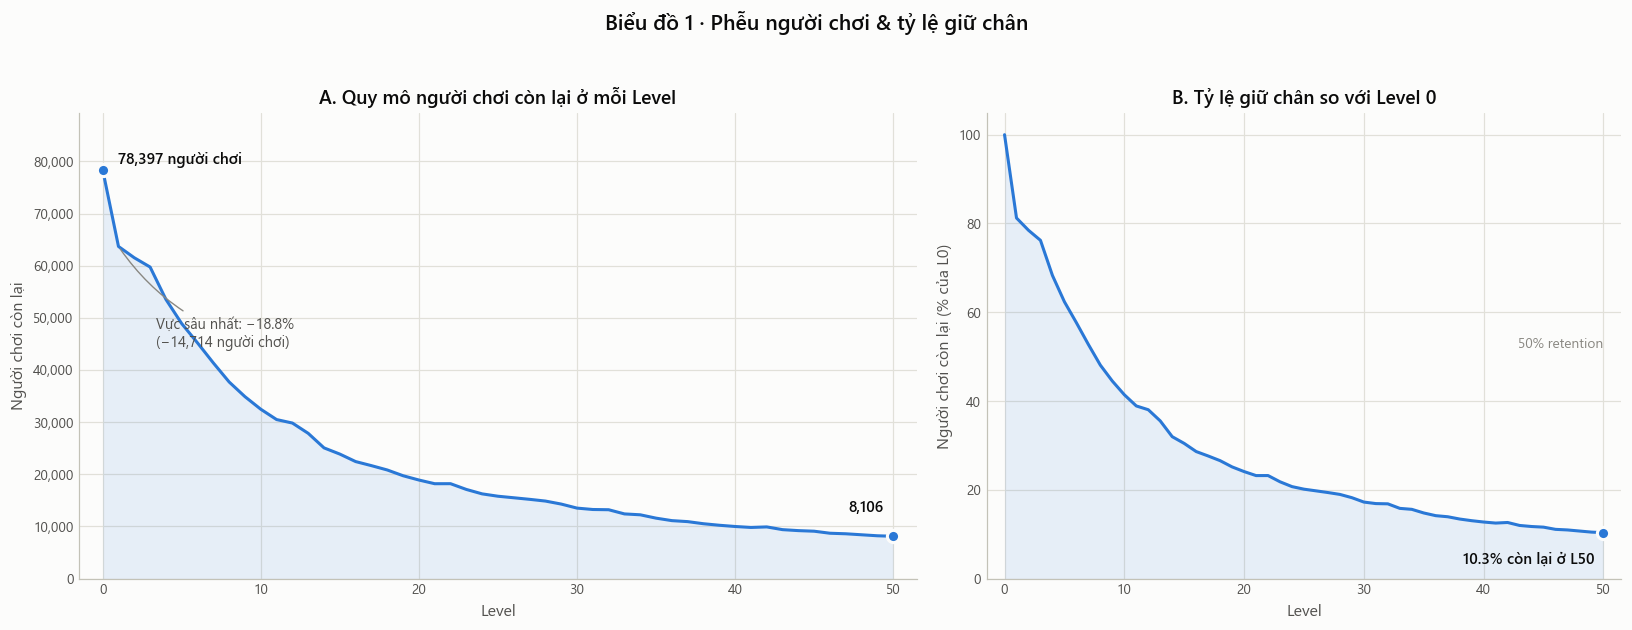

In [5]:
# =====================================================================
# BIỂU ĐỒ 1 — PLAYER VOLUME / RETENTION CURVE
# =====================================================================
d0 = df["Drop_off_by_level"].iloc[0]
d1 = df["Drop_off_by_level"].iloc[1]
dN = df["Drop_off_by_level"].iloc[-1]

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [1.32, 1]})

# --- Panel A: số người chơi còn lại (area + line) ----------------------
ax1.fill_between(df["Level"], df["Drop_off_by_level"],
                 color=BLUE, alpha=0.10, linewidth=0, zorder=1)
ax1.plot(df["Level"], df["Drop_off_by_level"], color=BLUE, zorder=3)

# Điểm đầu & điểm cuối có vòng nền 2px để nổi lên đường
ax1.plot([df["Level"].iloc[0]], [d0], "o", ms=8, color=BLUE,
         mec=SURFACE, mew=2, zorder=5)
ax1.plot([df["Level"].iloc[-1]], [dN], "o", ms=8, color=BLUE,
         mec=SURFACE, mew=2, zorder=5)

# Nhãn trực tiếp — chỉ ở điểm đầu, điểm cuối và điểm "gai" (chọn lọc)
ax1.annotate(f"{d0:,} người chơi", xy=(0, d0), xytext=(10, 4),
             textcoords="offset points", color=INK, fontsize=10, fontweight="semibold")
ax1.annotate(f"{dN:,}", xy=(50, dN), xytext=(-6, 16),
             textcoords="offset points", color=INK, fontsize=10,
             fontweight="semibold", ha="right")
ax1.annotate(
    f"Vực sâu nhất: −{100 * (1 - d1 / d0):.1f}%\n(−{d0 - d1:,} người chơi)",
    xy=(1, d1), xytext=(3.4, 44500), color=INK_2, fontsize=9.5,
    arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.9,
                    connectionstyle="arc3,rad=-0.15"))

ax1.set_title("A. Quy mô người chơi còn lại ở mỗi Level")
ax1.set_xlabel("Level")
ax1.set_ylabel("Người chơi còn lại")
ax1.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:,.0f}"))
ax1.set_xlim(-1.5, 51.5)
ax1.set_ylim(0, d0 * 1.14)
style_axes(ax1)

# --- Panel B: tỷ lệ giữ chân -----------------------------------------
ax2.plot(df["Level"], df["Retention_pct"], color=BLUE, zorder=3)
ax2.fill_between(df["Level"], 0, df["Retention_pct"],
                 color=BLUE, alpha=0.10, linewidth=0, zorder=1)
ax2.plot([50], [df["Retention_pct"].iloc[-1]], "o", ms=8, color=BLUE,
         mec=SURFACE, mew=2, zorder=5)
ax2.annotate(f"{df['Retention_pct'].iloc[-1]:.1f}% còn lại ở L50",
             xy=(50, df["Retention_pct"].iloc[-1]), xytext=(-6, -20),
             textcoords="offset points", color=INK, fontsize=10,
             fontweight="semibold", ha="right")
ax2.text(50, 52, "50% retention", color=MUTED, fontsize=9, ha="right")
ax2.set_title("B. Tỷ lệ giữ chân so với Level 0")
ax2.set_xlabel("Level")
ax2.set_ylabel("Người chơi còn lại (% của L0)")
ax2.set_xlim(-1.5, 51.5)
ax2.set_ylim(0, 105)
style_axes(ax2)

fig.suptitle("Biểu đồ 1 · Phễu người chơi & tỷ lệ giữ chân",
             fontsize=14, fontweight="semibold", color=INK, y=1.02)
fig.tight_layout()
plt.show()

#### 🔍 Nhận xét Biểu đồ 1 — *Key Takeaways*

1. **Đường cong "L-shape" cổ điển, và vực sâu nhất nằm ở L0 → L1.** Người chơi
   rơi từ **78.397** xuống **63.683** ngay level đầu tiên — mất **18,8%** (14.714 người)
   trong một bước. Đây là cú sốc onboarding: level đầu tiên thường quá dễ, người chơi
   thử rồi bỏ ngay thay vì tiếp tục.
2. **58,6% người chơi biến mất ngay trong 10 level đầu** (78.397 → 32.468). Từ L4 trở đi
   tỷ lệ rụng ổn định quanh **3,8 – 4,1%/level** — không còn cú sốc nào nữa.
3. **Tổng thất thoát 89,7%** từ L0 → L50 (còn lại 8.106 người, tương đương 10,3%).
4. ⚠️ **Đường cong không hoàn toàn đơn điệu** — có hiện tượng *người chơi quay lại*
   ở L22 (17.088 → 18.191) và L42 (9.798 → 9.901). Tức là một phần người chơi đã rơi
   đã **quay lại chơi tiếp** level đó (có thể do mở khoá thêm điều kiện, hoặc người
   chơi mới bù vào). Đây là tín hiệu tốt — game vẫn giữ được lượng người chơi quay lại.

> **Hàm động:** ở các level rơi sâu, thường lý do là *chưa hiểu cơ chế* (người chơi mới)
> chứ không phải *quá khó* (người chơi cũ). Vì vậy level 1–3 nên tối ưu cho
> **sự dễ đọc & hướng dẫn**, không phải độ khó.

---
### 📊 Biểu đồ 2 — So sánh tổng số lượt chơi thắng vs thua

* **Loại:** Hai panel chia sẻ trục X (small multiples) — thanh cột cho lượt thắng và lượt thua.
* **Trục X:** Level · **Trục Y:** Số lượt chơi.
* **Vì sao không dùng biểu đồ cột chồng?** Vì `Win_count` (tới 65.170) áp đảo `Lose_count`
  (tối đa 8.090) — phần "thua" sẽ bị chôn hoàn toàn và ta **không nhìn thấy** các gai nhọn,
  đúng thứ cần tìm. Tách 2 panel giữ nguyên cùng một thang đo (số lượt) nên vẫn
  trực tiếp so sánh được, mà gai nhọn thì lộ ra rõ.

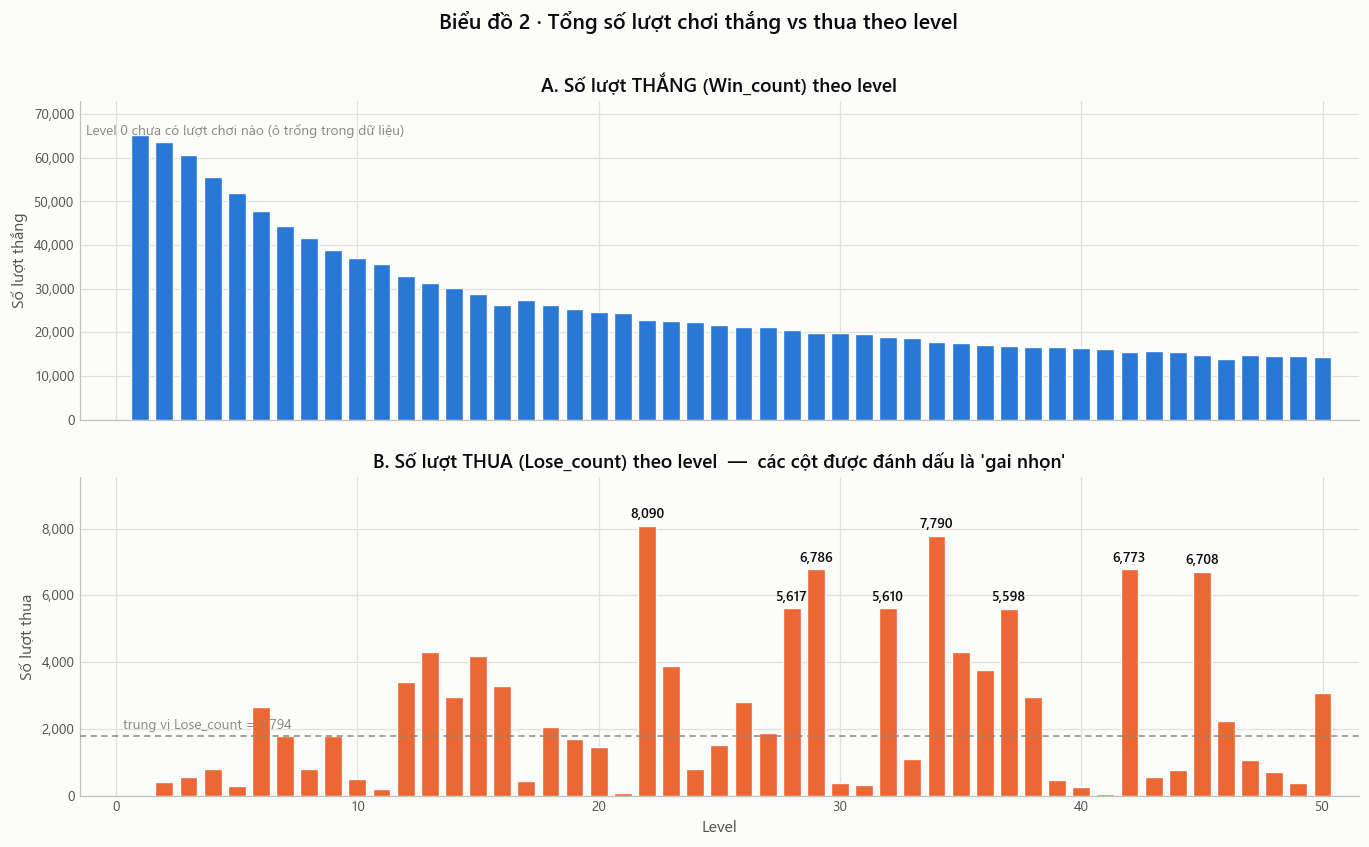

In [6]:
# =====================================================================
# BIỂU ĐỒ 2 — WIN vs LOSE ATTEMPT VOLUME
# =====================================================================
fig, (axw, axl) = plt.subplots(
    2, 1, figsize=(15, 8.2), sharex=True,
    gridspec_kw={"height_ratios": [1, 1], "hspace": 0.18})

BAR_W = 0.74   # để lại khe hở, không lấp kín ô (mark mảnh, có không gian thở)

# --- Panel trên: lượt THẮNG ------------------------------------------
axw.bar(df["Level"], df["Win_count"], width=BAR_W, color=BLUE,
        edgecolor=SURFACE, linewidth=0.9, zorder=3)
axw.set_title("A. Số lượt THẮNG (Win_count) theo level")
axw.set_ylabel("Số lượt thắng")
axw.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:,.0f}"))
axw.set_ylim(0, df["Win_count"].max() * 1.12)
axw.text(0.005, 0.93, "Level 0 chưa có lượt chơi nào (ô trống trong dữ liệu)",
         transform=axw.transAxes, color=MUTED, fontsize=9, va="top")
style_axes(axw)

# --- Panel dưới: lượt THUA -------------------------------------------
axl.bar(df["Level"], df["Lose_count"], width=BAR_W, color=ORANGE,
        edgecolor=SURFACE, linewidth=0.9, zorder=3)

# Đường ngưỡng: trung vị Lose_count (dùng để định nghĩa "gai nhọn")
med = df["Lose_count"].median()
axl.axhline(med, color=MUTED, lw=1.0, ls=(0, (4, 3)), zorder=4)
axl.text(0.3, med + 120, f"trung vị Lose_count = {med:,.0f}",
         color=MUTED, fontsize=9, va="bottom")

# Nhãn trực tiếp CHỈ trên các level gai nhọn (chọn lọc, không dán số lên mọi cột)
for _, r in df[df["Is_spike"]].iterrows():
    axl.annotate(f"{int(r['Lose_count']):,}", xy=(r["Level"], r["Lose_count"]),
                 xytext=(0, 5), textcoords="offset points", ha="center",
                 color=INK, fontsize=9, fontweight="semibold", zorder=6)

axl.set_title("B. Số lượt THUA (Lose_count) theo level  —  các cột được đánh dấu là 'gai nhọn'")
axl.set_xlabel("Level")
axl.set_ylabel("Số lượt thua")
axl.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:,.0f}"))
axl.set_ylim(0, df["Lose_count"].max() * 1.18)
axl.set_xlim(-1.5, 51.5)
style_axes(axl)

fig.suptitle("Biểu đồ 2 · Tổng số lượt chơi thắng vs thua theo level",
             fontsize=14, fontweight="semibold", color=INK, y=0.98)
plt.show()

#### 🔍 Nhận xét Biểu đồ 2 — *Key Takeaways*

1. **Có 8 "gai nhọn" rõ rệt** — định nghĩa bằng `Lose_count ≥ 3 × trung vị`:
   **L22, L28, L29, L32, L34, L37, L42, L45**. Đỉnh cao nhất là **L22 với 8.090 lượt thua**.
2. **Tại các level gai nhọn, tỷ lệ thua là 26,7%** trong tổng số lượt chơi, so với
   **chỉ 6,4%** ở các level còn lại — tức **gấp 4,2 lần**. Đây không phải nhiễu nền,
   mà là một đường cầu thang hằng định: mỗi lần người chơi tới level mới, họ phải
   "vượt ẩn" một chướng ngại cố ý.
3. ❌ **Giả thuyết "gai nhọn nằm ở bội số của 10" KHÔNG đúng với dữ liệu này.**
   L10/20/30/40/50 có số lượt thua trung bình **1.130**, thấp hơn trung vị toàn bảng
   (1.794) tới **37%**. Gai nhọn thật sự nằm ở **L22, L28–29, L32, L34, L37, L42, L45** —
   một chu kỳ **~6–7 level** (22 → 28 → 34 → 37/42 → 45), gần với mẫu số 7.
4. **Lượt thắng giảm đều và trơn tru** theo level, không có gai — nghĩa là *độ khó*
   đang được điều chỉnh tốt cho phần lớn người chơi; vấn đề chỉ nằm ở một vài
   chướng ngại cụ thể.

> **Hàm động:** rà soát 8 level gai nhọn trước — ưu tiên **L22** (đỉnh cao nhất) và
> **L34** (7.790). Nếu một level gai nhọn có tỷ lệ thua cao *nhưng* thời gian chơi
> thua vẫn bình thường, nguyên nhân nhiều khả năng là **lỗi thiết kế/UI** (người chơi
> hiểu sai luật) hơn là độ khó thuần túy.

---
### ⏱️ Biểu đồ 3 — Thời gian chơi trung bình theo kết quả

* **Loại:** Biểu đồ đường đôi (Grouped Line Chart) — 2 đường, chung trục Y.
* **Trục X:** Level · **Trục Y:** Thời gian chơi (giây).
* Cả hai đường **cùng đơn vị (giây)** nên dùng chung một trục Y — không cần trục kép.

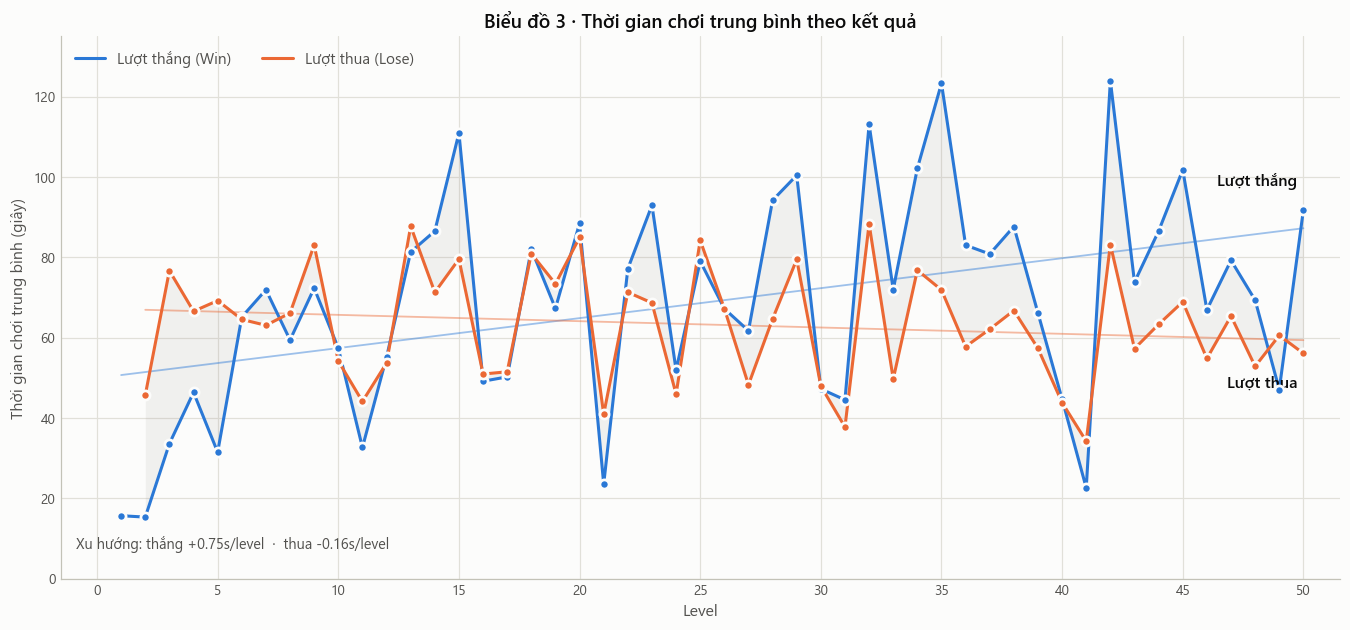

In [7]:
# =====================================================================
# BIỂU ĐỒ 3 — PLAY TIME COMPARISON (WIN vs LOSE)
# =====================================================================
w = df[["Level", "Win_Play_time_s"]].dropna()
l = df[["Level", "Lose_Play_time_s"]].dropna()

fig, ax = plt.subplots(figsize=(15, 6.4))

# Vùng tô nhạt ở giữa hai đường -> thấy rõ khoảng cách đang thay đổi thế nào
ax.fill_between(df["Level"], df["Win_Play_time_s"], df["Lose_Play_time_s"],
                where=df["Lose_Play_time_s"].notna() & df["Win_Play_time_s"].notna(),
                color=MUTED, alpha=0.10, linewidth=0, zorder=1)

ax.plot(w["Level"], w["Win_Play_time_s"], color=BLUE, zorder=3, label="Lượt thắng (Win)")
ax.plot(l["Level"], l["Lose_Play_time_s"], color=ORANGE, zorder=3, label="Lượt thua (Lose)")

# Marker có vòng nền 2px để đọc được khi hai đường giao nhau
ax.plot(w["Level"], w["Win_Play_time_s"], "o", ms=6, color=BLUE,
        mec=SURFACE, mew=1.8, zorder=4)
ax.plot(l["Level"], l["Lose_Play_time_s"], "o", ms=6, color=ORANGE,
        mec=SURFACE, mew=1.8, zorder=4)

# Nhãn trực tiếp ở đầu cuối (hai đường tách nhau rõ ở mép phải)
ax.annotate("Lượt thắng", xy=(50, df["Win_Play_time_s"].iloc[-1]), xytext=(-4, 16),
            textcoords="offset points", color=INK, fontsize=10.5,
            fontweight="semibold", ha="right")
ax.annotate("Lượt thua", xy=(50, df["Lose_Play_time_s"].iloc[-1]), xytext=(-4, -22),
            textcoords="offset points", color=INK, fontsize=10.5,
            fontweight="semibold", ha="right")

# Đường xu hướng tuyến tính (mảnh, mờ) để đọc xu hướng tổng thể
for col, color in (("Win_Play_time_s", BLUE), ("Lose_Play_time_s", ORANGE)):
    s = df[["Level", col]].dropna()
    k, b = np.polyfit(s["Level"], s[col], 1)
    ax.plot(s["Level"], k * s["Level"] + b, color=color, lw=1.2,
            alpha=0.45, zorder=2)

# Ghi chú xu hướng bằng CHỮ (token mực), không dùng màu dữ liệu cho chữ
kw = np.polyfit(w["Level"], w["Win_Play_time_s"], 1)[0]
kl = np.polyfit(l["Level"], l["Lose_Play_time_s"], 1)[0]
ax.text(0.012, 0.055,
        f"Xu hướng: thắng {kw:+.2f}s/level  ·  thua {kl:+.2f}s/level",
        transform=ax.transAxes, color=INK_2, fontsize=9.5)

ax.set_title("Biểu đồ 3 · Thời gian chơi trung bình theo kết quả")
ax.set_xlabel("Level")
ax.set_ylabel("Thời gian chơi trung bình (giây)")
ax.set_xlim(-1.5, 51.5)
ax.set_ylim(0, 135)
ax.set_xticks(range(0, 51, 5))
style_axes(ax)

leg = ax.legend(loc="upper left", ncols=2, bbox_to_anchor=(0.0, 1.0))
for t in leg.get_texts():
    t.set_color(INK_2)

plt.show()

#### 🔍 Nhận xét Biểu đồ 3 — *Key Takeaways*

1. **Thời gian thắng TĂNG đều theo độ khó: +0,75 giây/level** (r = +0,41).
   Trung bình L1–25 là **59,9s**, L26–50 là **78,0s** — **tăng 30,3%**.
   Điều này khớp với trực giác: level cao cần nhiều bước đi hơn.
2. **Thời gian thua KHÔNG tăng — thậm chí GIẢM nhẹ: −0,16 giây/level** (r = −0,16).
   L1–25: **65,8s** → L26–50: **60,6s** (**−7,8%**).
3. 🔑 **Hệ quả quan trọng — hai nhóm level hành vi khác hẳn nhau:**

   | Nhóm level | Thời gian thua − thời gian thắng | Diễn giải |
   |---|---|---|
   | **L1–25** | **+4,0s** (thua dài hơn ở 13/24 level) | Thua vì **chưa hiểu / làm sai** → cố thử lại nhiều lần → dài hơn |
   | **L26–50** | **−17,4s** (thua ngắn hơn ở 21/25 level) | Thua vì **đánh bại nhanh** → bỏ luôn, không thử lại |

4. **Càng lên cao, người chơi càng "buông" nhanh hơn.** Ở level thấp, thua còn đáng để
   thử tiếp; ở level cao, thua một lần là họ thoát — dấu hiệu **mất kết nối với
   nội dung** chứ không phải chỉ khó hơn.

> **Hàm động:** hai vấn đề tách biệt, cần hai cách xử lý tách biệt —
> • **Level 1–25:** lượt thua dài hơn lượt thắng ⇒ **lỗi hiểu luật**. Cần làm rõ
>   luật chơi, thêm animation/hint, hoặc chế độ tập luyện cho level mới.
> • **Level 26–50:** lượt thua ngắn hơn lượt thắng ⇒ **người chơi bỏ cuộc**. Cần cân
>   bằng lại độ khó, thêm phần thưởng/điểm số tích lũy, hoặc cơ chế "gợi ý sau khi thua".

---
### 🔥 Biểu đồ 4 — Ma trận tương quan (Correlation Matrix)

* **Loại:** Heatmap tương quan (`sns.heatmap`) — bảng màu **phân kỳ** xanh ↔ đỏ, điểm giữa
  xám trung tính (tương quan 0 = "không có gì"), cùng giá trị in ngay trong ô.
* **Các biến:** Level, Drop off by level, Win Play time, Win_count, Lose Play time, Lose_count.

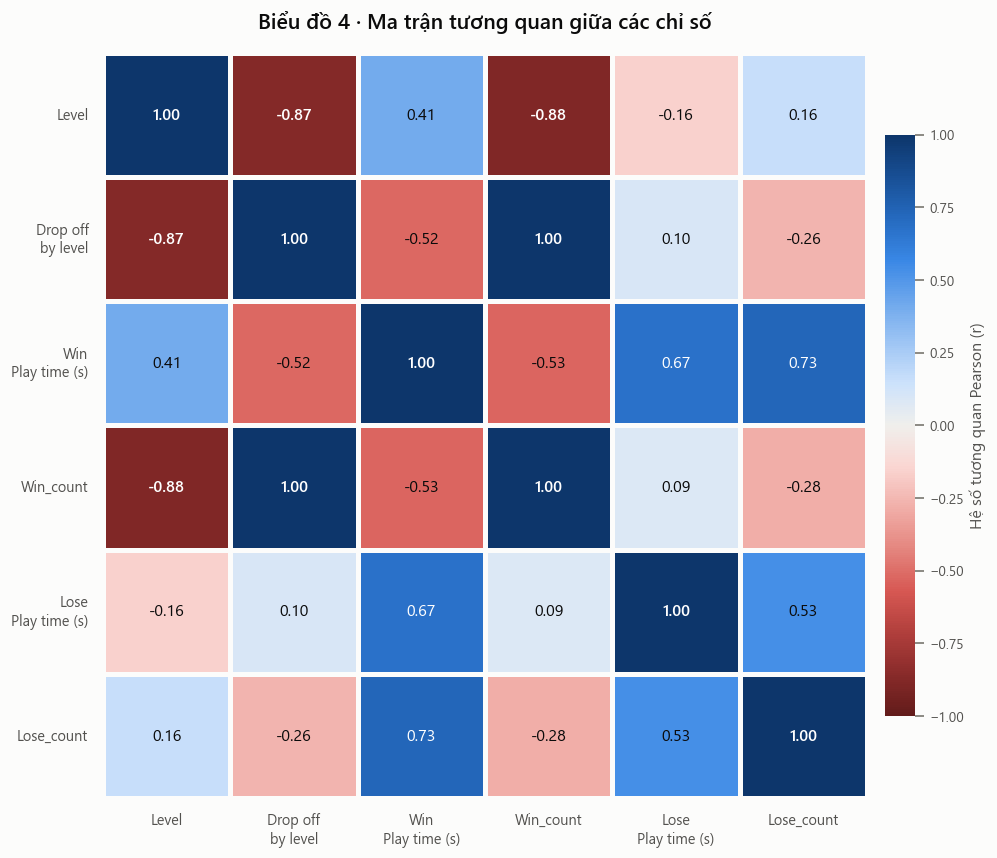

Bảng tương quan (số thô):
                   Level  Drop_off_by_level  Win_Play_time_s  Win_count  Lose_Play_time_s  Lose_count
Level              1.000             -0.869            0.407     -0.884            -0.161       0.162
Drop_off_by_level -0.869              1.000           -0.517      0.999             0.100      -0.259
Win_Play_time_s    0.407             -0.517            1.000     -0.528             0.672       0.732
Win_count         -0.884              0.999           -0.528      1.000             0.086      -0.282
Lose_Play_time_s  -0.161              0.100            0.672      0.086             1.000       0.532
Lose_count         0.162             -0.259            0.732     -0.282             0.532       1.000


In [8]:
# =====================================================================
# BIỂU ĐỒ 4 — CORRELATION MATRIX
# =====================================================================
CORNAMES = ["Level", "Drop_off_by_level", "Win_Play_time_s", "Win_count",
            "Lose_Play_time_s", "Lose_count"]
SHORT = ["Level", "Drop off\nby level", "Win\nPlay time (s)", "Win_count",
         "Lose\nPlay time (s)", "Lose_count"]

corr = df[CORNAMES].corr()

fig, ax = plt.subplots(figsize=(10.8, 8.8))
sns.heatmap(
    corr, ax=ax, cmap=DIVERGING, vmin=-1, vmax=1, center=0,
    annot=True, fmt=".2f",
    linewidths=2, linecolor=SURFACE,          # khe hở 2px màu nền giữa các ô
    annot_kws={"size": 10.5},
    cbar_kws={"label": "Hệ số tương quan Pearson (r)", "shrink": 0.78, "pad": 0.02},
    xticklabels=SHORT, yticklabels=SHORT,
)
ax.set_title("Biểu đồ 4 · Ma trận tương quan giữa các chỉ số", pad=16,
             fontsize=14, fontweight="semibold", color=INK)
ax.tick_params(axis="x", rotation=0, labelsize=9.5)
ax.tick_params(axis="y", rotation=0, labelsize=9.5)
ax.set_xticklabels(ax.get_xticklabels(), color=INK_2)
ax.set_yticklabels(ax.get_yticklabels(), color=INK_2)

# Chữ trong ô: chọn trắng/ink theo độ sáng của ô (bảo đảm tương phản)
for t in ax.texts:
    v = float(t.get_text())
    t.set_color("#ffffff" if abs(v) >= 0.55 else INK)
    t.set_fontweight("semibold" if abs(v) >= 0.75 else "normal")

plt.show()

# Bảng số (table view) — mọi giá trị đều đọc được bằng chữ, không phụ thuộc màu
print("Bảng tương quan (số thô):")
print(corr.round(3).to_string())

#### 🔍 Nhận xét Biểu đồ 4 — *Key Takeaways*

1. **`Drop_off_by_level` và `Win_count` gần như trùng nhau: r = +0,999.**
   Hai chỉ số này gần như **cùng một đường cong** — `Win_count` chính là số lượt thắng
   của những người chơi còn lại (cộng thêm phần thử lại). Về mặt thống kê chúng là
   **một biến**, không phải hai — đừng diễn giải "người chơi còn lại tăng thì có nhiều
   lượt thắng hơn" như một phát hiện, vì đó là đẳng tính.
2. **`Win_Play_time_s` ↔ `Lose_count`: r = +0,73** — mối quan hệ mạnh nhất trong ma trận.
   **Level càng khó thì lượt thua càng nhiều**, và chính những level đó cũng có thời gian
   chơi dài hơn. Nói cách khác: **gai nhọn đi kèm thời gian chơi dài** → đây là
   "chông chân" thực sự (bị kẹt ở một chướng ngại), chứ không phải thua nhanh rồi bỏ.
3. **`Win_Play_time_s` ↔ `Lose_Play_time_s`: r = +0,67** — hai lượt chơi ở cùng một level
   thường kéo dài tương tự nhau. Người chơi **ở lại lâu** ở level khó, dù thắng hay thua.
4. **`Level` ↔ `Drop_off_by_level`: r = −0,87** — xác nhận phễu: level càng cao, người
   chơi còn lại càng ít. **`Level` ↔ `Win_Play_time_s`: r = +0,41** — level càng cao thì
   càng tốn thời gian (yếu hơn hồi quy về mức +0,75s/level ở Biểu đồ 3, vì chỉ số này
   bị nhiễu bởi các level gai nhọn).
5. ⚠️ **`Lose_count` ↔ `Drop_off_by_level`: r = −0,26 (âm nhẹ).** Nghe có vẻ ngược đời
   nhưng hợp lý: level nào *nhiều người thua* thì người ta **ở lại thử lại** nhiều hơn
   thay vì bỏ đi — nên số người còn lại giữ được cao hơn một chút so với mức "thua nhiều
   = bỏ nhiều" mà ta thường mặc định.
6. ⚠️ **Cảnh báo về mối tương quan giả:** `Level` và `Win_count` (r = −0,88) đều là
   **biến vị trí trong phễu**, nên chúng tương quan mạnh với nhau một cách *máy móc*.
   Tương tự, `Win_Play_time_s` ↔ `Lose_count` (r = +0,73) có thể chỉ là hệ quả của
   việc level khó vừa khiến người ta ở lâu hơn vừa thua nhiều hơn — cần kiểm chứng
   bằng thí nghiệm A/B, không kết luận từ tương quan.

---
### 🖥️ Dashboard tổng quan — 4 biểu đồ trong 1 khung

Kèm dải **stat tile** ở trên: 4 con số then chốt của toàn bộ dữ liệu.

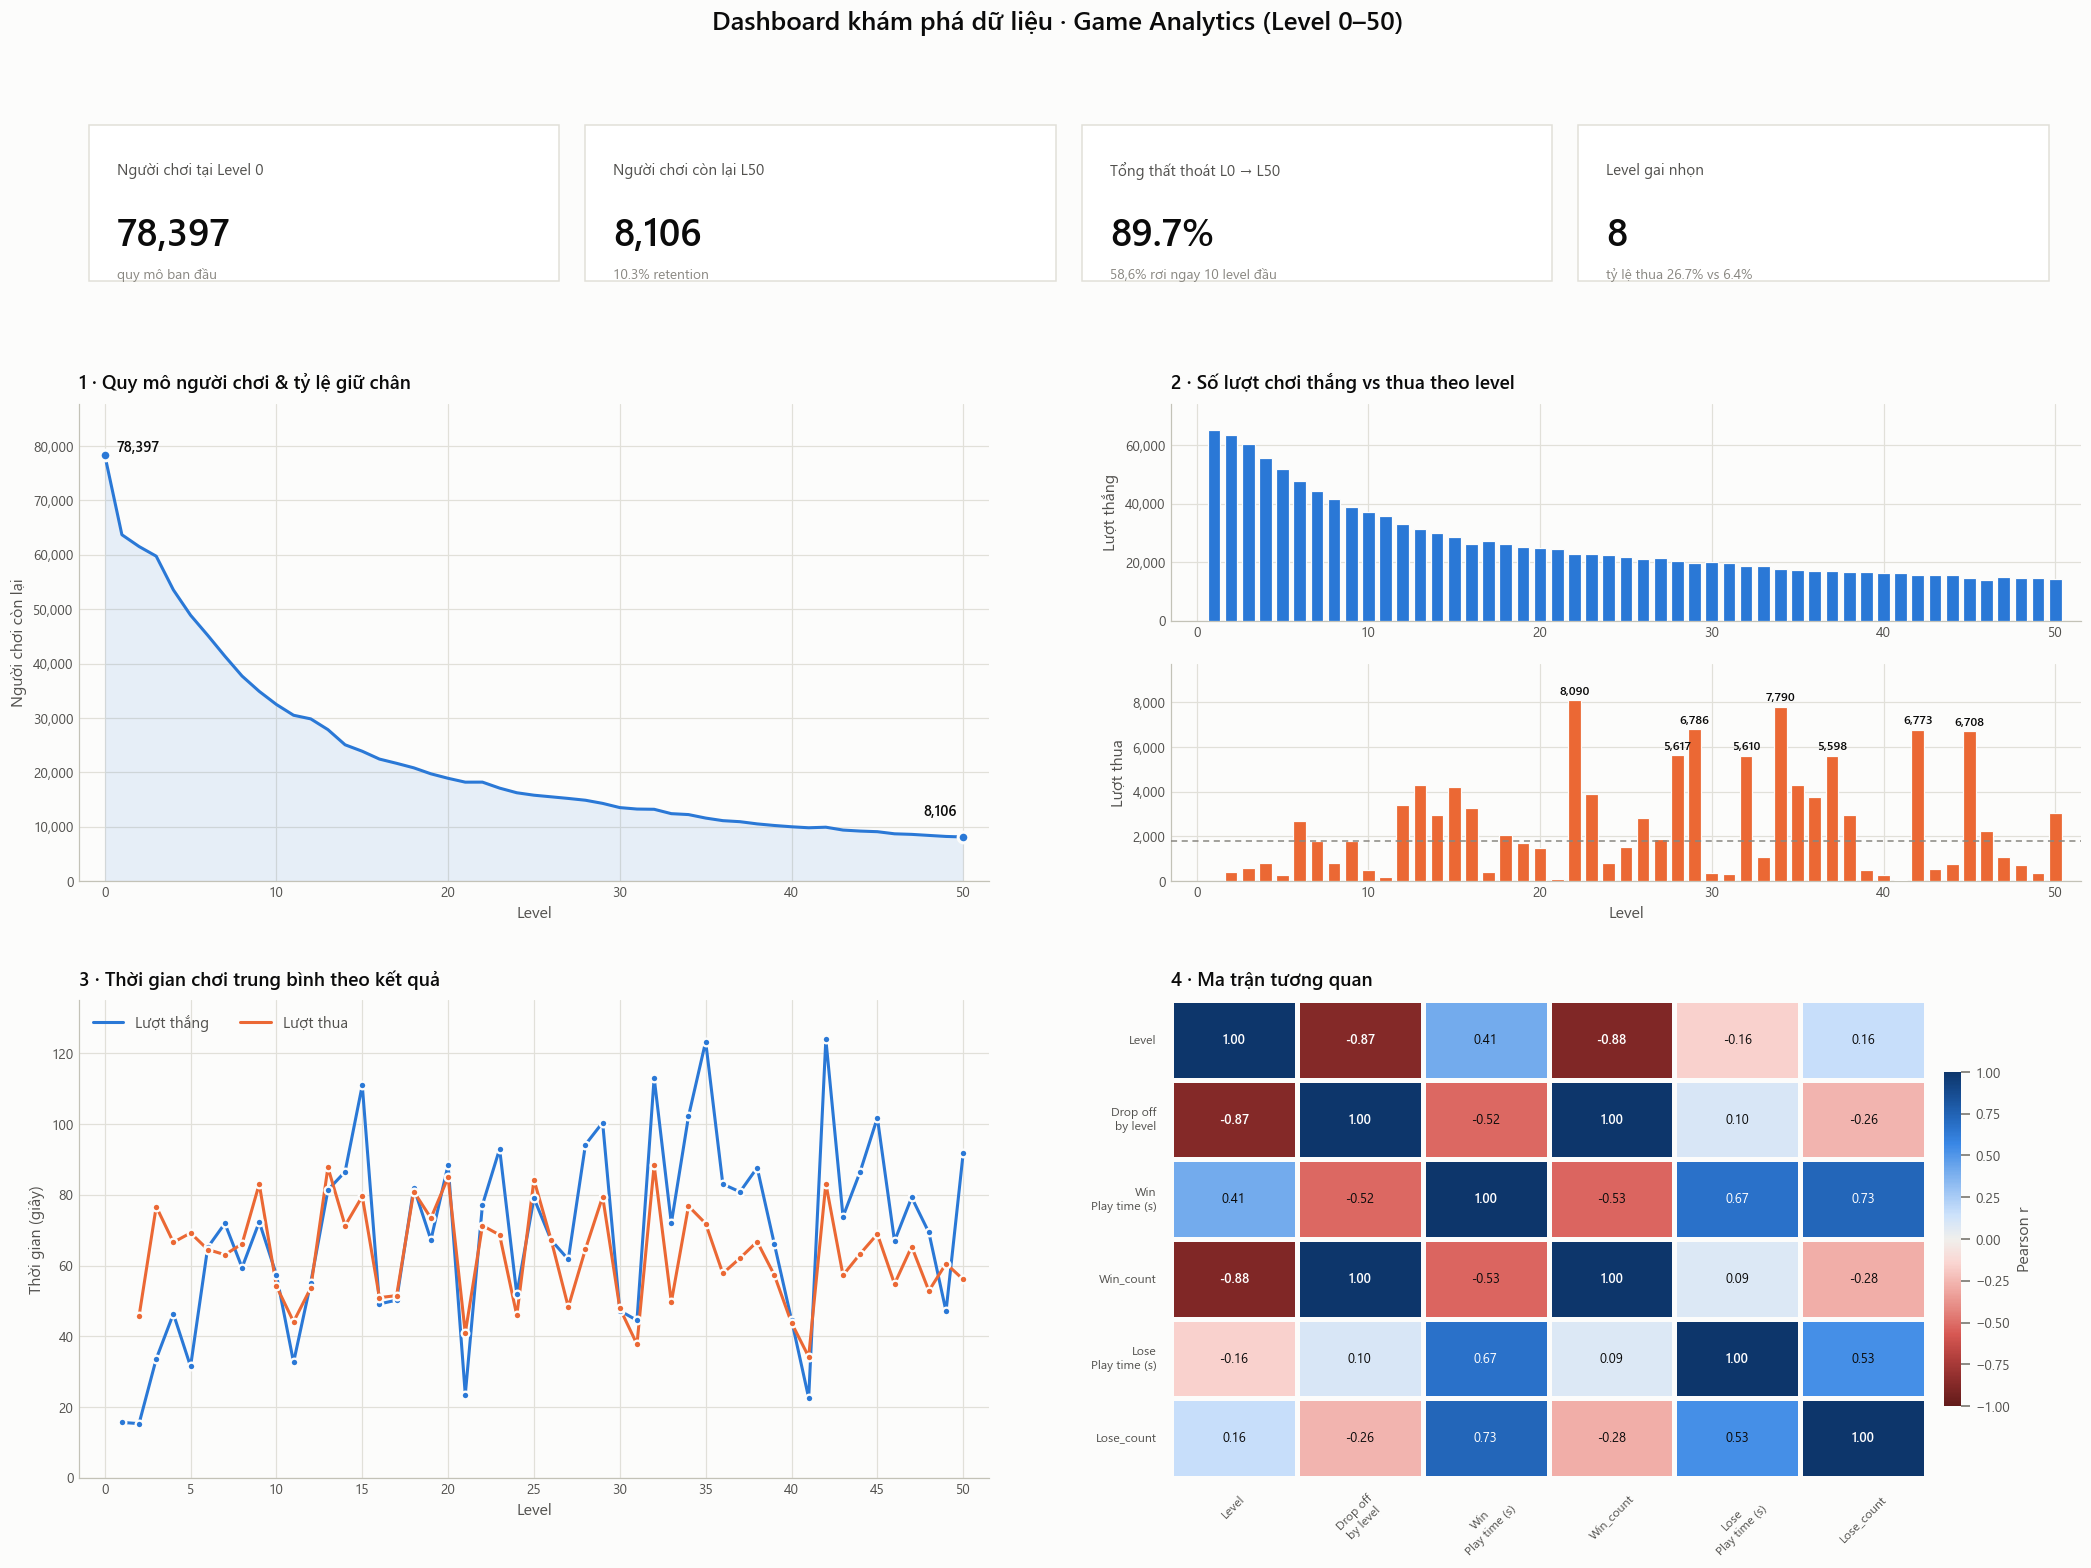

In [9]:
# =====================================================================
# DASHBOARD TỔNG QUAN 2x2 + DẢI KPI
# =====================================================================
fig = plt.figure(figsize=(20, 14.5))
gs = fig.add_gridspec(3, 2, height_ratios=[0.34, 1, 1],
                      hspace=0.32, wspace=0.20,
                      left=0.055, right=0.965, top=0.905, bottom=0.055)

# ---------- Dải KPI (stat tiles) --------------------------------------
ax_kpi = fig.add_subplot(gs[0, :])
ax_kpi.set_axis_off()
ax_kpi.set_xlim(0, 1); ax_kpi.set_ylim(0, 1)

kpi_items = [
    ("Người chơi tại Level 0", f"{df['Drop_off_by_level'].iloc[0]:,}", "quy mô ban đầu"),
    ("Người chơi còn lại L50", f"{df['Drop_off_by_level'].iloc[-1]:,}",
     f"{df['Retention_pct'].iloc[-1]:.1f}% retention"),
    ("Tổng thất thoát L0 → L50",
     f"{100 * (1 - df['Drop_off_by_level'].iloc[-1] / df['Drop_off_by_level'].iloc[0]):.1f}%",
     "58,6% rơi ngay 10 level đầu"),
    ("Level gai nhọn", f"{len(SPIKES)}",
     f"tỷ lệ thua {df.loc[df['Is_spike'], 'Lose_share_pct'].mean():.1f}% vs "
     f"{df.loc[~df['Is_spike'], 'Lose_share_pct'].mean():.1f}%"),
]
for i, (lab, val, sub) in enumerate(kpi_items):
    x0 = 0.005 + i * 0.248
    ax_kpi.add_patch(plt.Rectangle((x0, 0.02), 0.235, 0.96, transform=ax_kpi.transAxes,
                                   facecolor="#ffffff", edgecolor=GRID, lw=1.0,
                                   zorder=1, clip_on=False))
    ax_kpi.text(x0 + 0.014, 0.70, lab, transform=ax_kpi.transAxes,
                color=INK_2, fontsize=10, va="center", zorder=2)
    ax_kpi.text(x0 + 0.014, 0.30, val, transform=ax_kpi.transAxes,
                color=INK, fontsize=25, fontweight="semibold", va="center", zorder=2)
    ax_kpi.text(x0 + 0.014, 0.02, sub, transform=ax_kpi.transAxes,
                color=MUTED, fontsize=9, va="bottom", zorder=2)

# ---------- (0,0) Biểu đồ 1: phễu người chơi --------------------------
ax1 = fig.add_subplot(gs[1, 0])
ax1.fill_between(df["Level"], df["Drop_off_by_level"], color=BLUE,
                 alpha=0.10, linewidth=0, zorder=1)
ax1.plot(df["Level"], df["Drop_off_by_level"], color=BLUE, zorder=3)
ax1.plot([0, 50], [df["Drop_off_by_level"].iloc[0], df["Drop_off_by_level"].iloc[-1]],
         "o", ms=7, color=BLUE, mec=SURFACE, mew=2, zorder=5)
ax1.annotate(f"{df['Drop_off_by_level'].iloc[0]:,}", xy=(0, df["Drop_off_by_level"].iloc[0]),
             xytext=(8, 2), textcoords="offset points", color=INK, fontsize=9.5,
             fontweight="semibold")
ax1.annotate(f"{df['Drop_off_by_level'].iloc[-1]:,}", xy=(50, df["Drop_off_by_level"].iloc[-1]),
             xytext=(-4, 14), textcoords="offset points", color=INK, fontsize=9.5,
             fontweight="semibold", ha="right")
ax1.set_title("1 · Quy mô người chơi & tỷ lệ giữ chân", loc="left", pad=10)
ax1.set_xlabel("Level"); ax1.set_ylabel("Người chơi còn lại")
ax1.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:,.0f}"))
ax1.set_xlim(-1.5, 51.5); ax1.set_ylim(0, df["Drop_off_by_level"].iloc[0] * 1.12)
style_axes(ax1)

# ---------- (0,1) Biểu đồ 2: win vs lose (2 panel) ---------------------
gs2 = gs[1, 1].subgridspec(2, 1, hspace=0.20)
axw = fig.add_subplot(gs2[0])
axl = fig.add_subplot(gs2[1], sharex=axw)

axw.bar(df["Level"], df["Win_count"], width=0.74, color=BLUE,
        edgecolor=SURFACE, linewidth=0.8, zorder=3)
axw.set_title("2 · Số lượt chơi thắng vs thua theo level", loc="left", pad=10)
axw.set_ylabel("Lượt thắng")
axw.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:,.0f}"))
axw.set_ylim(0, df["Win_count"].max() * 1.14)
style_axes(axw)

axl.bar(df["Level"], df["Lose_count"], width=0.74, color=ORANGE,
        edgecolor=SURFACE, linewidth=0.8, zorder=3)
axl.axhline(df["Lose_count"].median(), color=MUTED, lw=1.0, ls=(0, (4, 3)), zorder=4)
for _, r in df[df["Is_spike"]].iterrows():
    axl.annotate(f"{int(r['Lose_count']):,}", xy=(r["Level"], r["Lose_count"]),
                 xytext=(0, 4), textcoords="offset points", ha="center",
                 color=INK, fontsize=8, fontweight="semibold", zorder=6)
axl.set_ylabel("Lượt thua")
axl.set_xlabel("Level")
axl.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:,.0f}"))
axl.set_ylim(0, df["Lose_count"].max() * 1.20)
axl.set_xlim(-1.5, 51.5)
style_axes(axl)

# ---------- (1,0) Biểu đồ 3: thời gian chơi ----------------------------
ax3 = fig.add_subplot(gs[2, 0])
ax3.plot(w["Level"], w["Win_Play_time_s"], color=BLUE, zorder=3,
         label="Lượt thắng")
ax3.plot(l["Level"], l["Lose_Play_time_s"], color=ORANGE, zorder=3,
         label="Lượt thua")
ax3.plot(w["Level"], w["Win_Play_time_s"], "o", ms=5, color=BLUE,
         mec=SURFACE, mew=1.5, zorder=4)
ax3.plot(l["Level"], l["Lose_Play_time_s"], "o", ms=5, color=ORANGE,
         mec=SURFACE, mew=1.5, zorder=4)
ax3.set_title("3 · Thời gian chơi trung bình theo kết quả", loc="left", pad=10)
ax3.set_xlabel("Level"); ax3.set_ylabel("Thời gian (giây)")
ax3.set_xlim(-1.5, 51.5); ax3.set_ylim(0, 135)
ax3.set_xticks(range(0, 51, 5))
style_axes(ax3)
leg = ax3.legend(loc="upper left", ncols=2)
for t in leg.get_texts():
    t.set_color(INK_2)

# ---------- (1,1) Biểu đồ 4: ma trận tương quan -----------------------
ax4 = fig.add_subplot(gs[2, 1])
sns.heatmap(corr, ax=ax4, cmap=DIVERGING, vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", linewidths=2, linecolor=SURFACE,
            annot_kws={"size": 8.5},
            cbar_kws={"label": "Pearson r", "shrink": 0.70, "pad": 0.02},
            xticklabels=SHORT, yticklabels=SHORT)
ax4.set_title("4 · Ma trận tương quan", loc="left", pad=10)
ax4.tick_params(axis="x", rotation=45, labelsize=8)
ax4.tick_params(axis="y", rotation=0, labelsize=8)
ax4.set_xticklabels(ax4.get_xticklabels(), color=INK_2)
ax4.set_yticklabels(ax4.get_yticklabels(), color=INK_2)
for t in ax4.texts:
    v = float(t.get_text())
    t.set_color("#ffffff" if abs(v) >= 0.55 else INK)
    t.set_fontweight("semibold" if abs(v) >= 0.75 else "normal")

fig.suptitle("Dashboard khám phá dữ liệu · Game Analytics (Level 0–50)",
             fontsize=17, fontweight="semibold", color=INK, y=0.975)
plt.show()

---
### 📋 Bảng dữ liệu đầy đủ (table view)

Mọi giá trị trong các biểu đồ trên đều đọc được bằng chữ ở bảng này — không có giá trị
nào bị "khoá" sau tooltip.

In [10]:
# =====================================================================
# TABLE VIEW — toàn bộ chỉ số dẫn xuất theo từng level
# =====================================================================
table = df[[
    "Level", "Drop_off_by_level", "Retention_pct", "Drop_rate_pct",
    "Win_count", "Lose_count", "Lose_share_pct", "Attempts_per_player",
    "Win_Play_time_s", "Lose_Play_time_s",
]].copy()
table.columns = ["Level", "Drop_off", "Retention_%", "Drop_rate_%",
                 "Win_count", "Lose_count", "Lose_share_%", "Attempts/player",
                 "Win_time_s", "Lose_time_s"]
table["Gai_nhon"] = df["Is_spike"].map({True: "<<<", False: ""})

pd.set_option("display.max_rows", 100, "display.width", 200, "display.max_columns", 30)
print(table.round(2).to_string(index=False))

 Level  Drop_off  Retention_%  Drop_rate_%  Win_count  Lose_count  Lose_share_%  Attempts/player  Win_time_s  Lose_time_s Gai_nhon
     0     78397       100.00          NaN        NaN         NaN           NaN             0.00         NaN          NaN         
     1     63683        81.23        18.77    65170.0         NaN           NaN             1.02       15.65          NaN         
     2     61516        78.47         3.40    63584.0       404.0          0.63             1.04       15.30        45.68         
     3     59738        76.20         2.89    60562.0       564.0          0.92             1.02       33.59        76.67         
     4     53534        68.29        10.39    55594.0       798.0          1.42             1.05       46.36        66.56         
     5     48884        62.35         8.69    51853.0       292.0          0.56             1.07       31.47        69.21         
     6     45185        57.64         7.57    47704.0      2666.0          5.29    

---
## 🧭 Tổng kết & các bước tiếp theo đề xuất

### 4 điều đã biết chắc sau khi khám phá

| # | Phát hiện | Bằng chứng | Hàm động |
|---|---|---|---|
| 1 | **Vực rụng nằm ở level đầu, không nằm ở level khó** | L0→L1 mất **18,8%**; 10 level đầu mất **58,6%**; từ L4 trở đi chỉ ~4%/level | Tối ưu onboarding & hiểu luật cho level 1–3, **không** nâng độ khó |
| 2 | **8 level gai nhọn, tỷ lệ thua gấp 4,2× bình thường** | L22 (8.090), L34 (7.790), L29, L42, L45…; 26,7% vs 6,4% | Rà soát thiết kế 8 level này, ưu tiên L22 & L34 |
| 3 | **Hai nhóm level hành vi khác hẳn** | L1–25: thua **dài hơn** thắng +4,0s → lỗi hiểu luật · L26–50: thua **ngắn hơn** thắng −17,4s → bỏ cuộc | Thêm hint/hint động cho level thấp; cân bằng độ khó + phần thưởng tích lũy cho level cao |
| 4 | **Người chơi thử lại nhiều hơn theo độ khó** | attempts/player: **1,02** (L1) → **2,13** (L50), đỉnh **2,36** (L45) | Gắn "người chơi kiên trì" (multiplier tăng dần) — dấu hiệu engagement tốt |

### Câu hỏi chưa trả lời được từ dữ liệu này

1. **Không có cột "người chơi mới" vs "người chơi quay lại"** → chưa biết phễu suy giảm
   do *mất người* hay do *hết thời gian chơi*.
2. **Không có cột thời gian/ngày** → chưa biết lượt thua dài hơn ở level thấp là do
   *retry trong cùng phiên* hay *quay lại ngày hôm sau*.
3. **Không có cột lý do thua** → giả thuyết "lỗi UI/hiểu luật" ở level thấp mới chỉ là
   **suy đoán từ tương quan**, cần dữ liệu xác nhận.
4. **`Win_count` và `Drop_off_by_level` gần như trùng nhau (r = 0,999)** → cần thêm
   *cohort* hoặc *số phiên chơi* để tách "người" khỏi "lượt".

### Bước tiếp theo đề xuất

- **Phân tích cohort theo thời gian** (nếu có log phiên): tách *drop-off* thành
  *uninstall* vs *churn tạm thời* — đây là con số quyết định ưu tiên sản phẩm.
- **A/B test 3 chướng ngại lớn nhất** (L22, L34, L42): thử giảm 1 bậc độ khó, đo lại
  `Lose_count` và `Drop_rate_pct` ở nhóm thử.
- **Thêm sự kiện cho lượt thua ở level cao** (gợi ý sau khi thua) để đo tác động lên
  `Attempts_per_player` tại L26–50.
- **Kiểm tra lại level 1–3** (nơi mất 58,6% người chơi) bằng **playtest + video
  session**: nếu người chơi hiểu sai luật, đó là lỗi trình bày chứ không phải độ khó.

---

<sub>📌 Notebook dùng bảng màu đã kiểm chứng mù màu (protanopia/deuteranopia, Machado 2009):
`#2a78d6` / `#eb6834` — ΔE 24,7 (mục tiêu ≥ 8) · 33,6 thị lực thường (ngưỡng ≥ 15).
Bảng màu xanh lá–đỏ của *status* đã bị loại do ΔE 4,1.</sub>